# Part 2 — A Creative Target: My Initials "CL"

The same flow model is trained to carry Gaussian noise onto the letters CL, animated, and tested at different Euler step counts.

In [1]:
import json
import platform
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
import torch
import torch.nn as nn
from matplotlib.collections import LineCollection
from PIL import Image, ImageDraw, ImageFont

ROOT = Path.cwd()
OUT = ROOT / "outputs" / "part2"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

env = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "pillow": PIL.__version__,
    "pandas": pd.__version__,
    "device": "cpu",
    "cpu": platform.processor(),
    "platform": platform.platform(),
    "torch_threads": torch.get_num_threads(),
    "seed": SEED,
}
(OUT / "environment.json").write_text(json.dumps(env, indent=2))
env

{'python': '3.13.2',
 'torch': '2.14.0+cpu',
 'numpy': '2.2.2',
 'matplotlib': '3.11.1',
 'pillow': '12.3.0',
 'pandas': '2.2.3',
 'device': 'cpu',
 'cpu': 'Intel64 Family 6 Model 165 Stepping 2, GenuineIntel',
 'platform': 'Windows-11-10.0.26300-SP0',
 'torch_threads': 6,
 'seed': 0}

## Task 1 — "CL" as a 2D point distribution

"CL" is rendered in Arial Bold (a Windows system font, glyph shapes only) and thresholded into a foreground mask.

In [2]:
FONT_PATH = Path("C:/Windows/Fonts/arialbd.ttf")
TEXT, FONT_SIZE, PAD = "CL", 320, 12


def render_text_mask(text=TEXT, font_size=FONT_SIZE, pad=PAD):
    """Boolean (H, W) mask of the rendered text, cropped to its bounding box plus padding."""
    if FONT_PATH.exists():
        font = ImageFont.truetype(str(FONT_PATH), font_size)
    else:
        font = ImageFont.load_default(font_size)
    left, top, right, bottom = font.getbbox(text)
    img = Image.new("L", (right - left + 2 * pad, bottom - top + 2 * pad), 0)
    ImageDraw.Draw(img).text((pad - left, pad - top), text, fill=255, font=font)
    return np.array(img) > 127


MASK = render_text_mask()
H, W = MASK.shape
HALF_WIDTH = 3.0                       # the mask's width spans x in [-3, 3]
SCALE = W / (2 * HALF_WIDTH)           # pixels per coordinate unit
FG_ROWS, FG_COLS = np.nonzero(MASK)
FG = torch.tensor(np.stack([FG_COLS, FG_ROWS], 1), dtype=torch.float32)   # (n_fg, 2) as (col, row)
np.save(OUT / "target_mask.npy", MASK)

print(f"mask {W} x {H} px, {len(FG_ROWS)} foreground pixels ({MASK.mean():.1%} of the canvas)")
print(f"scale: {SCALE:.2f} px per unit, so one pixel = {1 / SCALE:.4f} units")
print(f"coordinate box: x in [{-W / 2 / SCALE:.2f}, {W / 2 / SCALE:.2f}], y in [{-H / 2 / SCALE:.2f}, {H / 2 / SCALE:.2f}]")

mask 451 x 261 px, 36383 foreground pixels (30.9% of the canvas)
scale: 75.17 px per unit, so one pixel = 0.0133 units
coordinate box: x in [-3.00, 3.00], y in [-1.74, 1.74]


### Sampling rule

Pick a foreground pixel uniformly, add in-pixel jitter, and map it to the plane so the letters span $x \in [-3, 3]$ with $y$ pointing up.

on-letter rate of target samples (sanity check, should be 1): 1.0


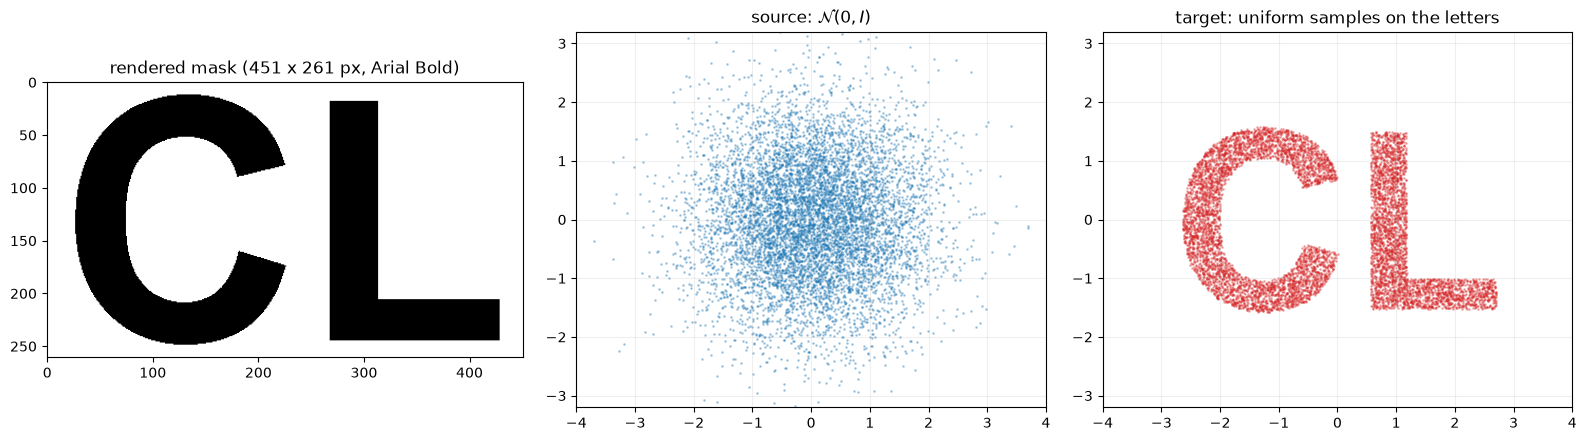

In [3]:
def pixels_to_xy(colrow):
    x = (colrow[:, 0] - W / 2) / SCALE
    y = (H / 2 - colrow[:, 1]) / SCALE
    return torch.stack([x, y], 1)


def sample_target(n, generator=None):
    idx = torch.randint(0, len(FG), (n,), generator=generator)
    return pixels_to_xy(FG[idx] + torch.rand(n, 2, generator=generator))


def sample_source(n, generator=None):
    return torch.randn(n, 2, generator=generator)


def on_letter_rate(points):
    """Fraction of points that fall on a foreground pixel of the target mask (outside the canvas counts as a miss)."""
    p = points.numpy() if torch.is_tensor(points) else points
    col = np.floor(p[:, 0] * SCALE + W / 2).astype(int)
    row = np.floor(H / 2 - p[:, 1] * SCALE).astype(int)
    inside = (col >= 0) & (col < W) & (row >= 0) & (row < H)
    hit = np.zeros(len(p), dtype=bool)
    hit[inside] = MASK[row[inside], col[inside]]
    return hit.mean()


tgt_demo = sample_target(8000, torch.Generator().manual_seed(1))
src_demo = sample_source(8000, torch.Generator().manual_seed(2))
print("on-letter rate of target samples (sanity check, should be 1):", on_letter_rate(tgt_demo))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].imshow(MASK, cmap="gray_r")
axes[0].set_title(f"rendered mask ({W} x {H} px, Arial Bold)")
axes[1].scatter(*src_demo.T, s=1, alpha=0.3, color="tab:blue")
axes[1].set_title("source: $\\mathcal{N}(0, I)$")
axes[2].scatter(*tgt_demo.T, s=1, alpha=0.3, color="tab:red")
axes[2].set_title("target: uniform samples on the letters")
for ax in axes[1:]:
    ax.set(xlim=(-4, 4), ylim=(-3.2, 3.2), aspect="equal")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUT / "task1_target.png", dpi=130, bbox_inches="tight")
plt.show()

### Model and training

Same MLP and random-pair training as Part 1, run for 30,000 steps because the letters have sharper detail.

In [4]:
class VelocityMLP(nn.Module):
    """v_theta(x, t): R^2 x [0, 1] -> R^2."""

    def __init__(self, hidden=128, depth=3):
        super().__init__()
        layers, d = [], 3
        for _ in range(depth):
            layers += [nn.Linear(d, hidden), nn.SiLU()]
            d = hidden
        layers.append(nn.Linear(d, 2))
        self.net = nn.Sequential(*layers)

    def forward(self, x, t):
        if not torch.is_tensor(t) or t.dim() == 0:
            t = torch.full((x.shape[0], 1), float(t))
        return self.net(torch.cat([x, t.reshape(-1, 1)], dim=1))


def random_pair_batch(n, g):
    x0, x1 = sample_source(n, g), sample_target(n, g)
    t = torch.rand(n, 1, generator=g)
    return (1 - t) * x0 + t * x1, t, x1 - x0


def train_flow(model, batch_fn, steps, batch_size=256, lr=1e-3, seed=0):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps, eta_min=lr * 0.05)
    losses = np.empty(steps)
    t_start = time.perf_counter()
    for step in range(steps):
        xt, t, u = batch_fn(batch_size, g)
        loss = ((model(xt, t) - u) ** 2).sum(1).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        losses[step] = loss.item()
    return losses, time.perf_counter() - t_start


@torch.no_grad()
def euler_sample(model, z0, n_steps, return_path=False):
    z = z0.clone()
    dt = 1.0 / n_steps
    path = [z.clone()] if return_path else None
    for k in range(n_steps):
        z = z + dt * model(z, k * dt)
        if return_path:
            path.append(z.clone())
    return (z, torch.stack(path)) if return_path else z


CONFIG = {"hidden": 128, "depth": 3, "activation": "SiLU", "batch_size": 256, "steps": 30000,
          "lr": 1e-3, "lr_schedule": "cosine to 5% of lr", "optimizer": "Adam", "seed": SEED,
          "coupling": "independent (random pairs)", "target": f"'{TEXT}' Arial Bold {FONT_SIZE}px, width -> [-3, 3]"}

CKPT = OUT / "cl_model.pt"
torch.manual_seed(SEED)
model = VelocityMLP(CONFIG["hidden"], CONFIG["depth"])
n_params = sum(p.numel() for p in model.parameters())
losses, train_seconds = train_flow(model, random_pair_batch, CONFIG["steps"], CONFIG["batch_size"], CONFIG["lr"], SEED)
model.eval()
torch.save({"state_dict": model.state_dict(), "config": CONFIG, "train_seconds": train_seconds}, CKPT)
np.save(OUT / "train_losses.npy", losses)
print(f"parameters: {n_params} | {CONFIG['steps']} steps in {train_seconds:.1f} s "
      f"({1000 * train_seconds / CONFIG['steps']:.2f} ms/step) | last-2000-step mean loss {losses[-2000:].mean():.3f}")

parameters: 33794 | 30000 steps in 162.7 s (5.42 ms/step) | last-2000-step mean loss 3.480


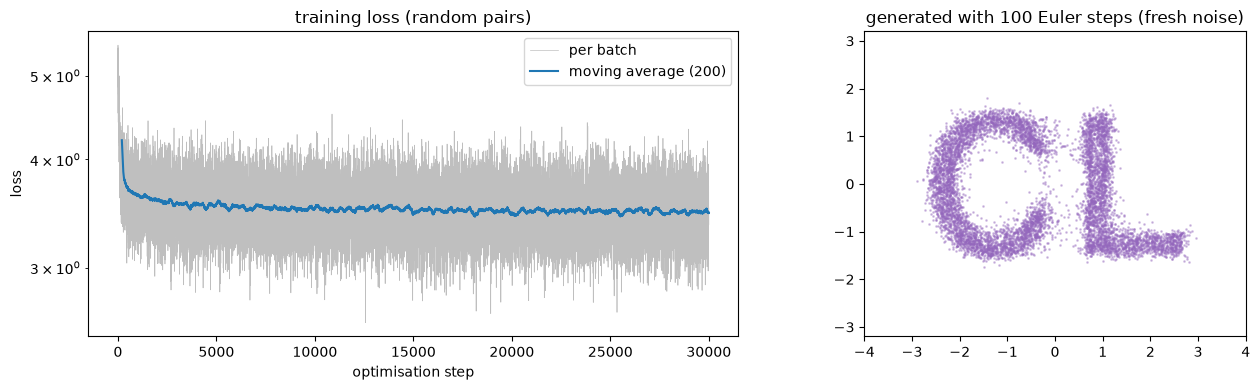

on-letter rate, 100 Euler steps: 0.91075


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(losses, color="0.75", lw=0.5, label="per batch")
axes[0].plot(np.arange(199, len(losses)), np.convolve(losses, np.ones(200) / 200, "valid"), label="moving average (200)")
axes[0].set(xlabel="optimisation step", ylabel="loss", yscale="log", title="training loss (random pairs)")
axes[0].legend()
z_check = euler_sample(model, sample_source(8000, torch.Generator().manual_seed(3)), 100)
axes[1].scatter(*z_check.T, s=1, alpha=0.35, color="tab:purple")
axes[1].set(xlim=(-4, 4), ylim=(-3.2, 3.2), aspect="equal", title="generated with 100 Euler steps (fresh noise)")
plt.tight_layout()
plt.savefig(OUT / "task1_training.png", dpi=130, bbox_inches="tight")
plt.show()
print("on-letter rate, 100 Euler steps:", on_letter_rate(z_check))

## Task 2 — Animating the learned transport

3,000 fixed particles are tracked through 100 Euler steps, and each one is coloured by its generated endpoint or by its starting angle. Colours are added after sampling and never used in training.

In [6]:
N_ANIM, K_ANIM = 3000, 100
z0_anim = sample_source(N_ANIM, torch.Generator().manual_seed(7))
t0 = time.perf_counter()
z1_anim, path_anim = euler_sample(model, z0_anim, K_ANIM, return_path=True)
print(f"integrated {N_ANIM} particles x {K_ANIM} steps in {time.perf_counter() - t0:.2f} s; path tensor {tuple(path_anim.shape)}")

end_val = (z1_anim[:, 0] + 0.4 * z1_anim[:, 1]).numpy()
end_val = (end_val - end_val.min()) / (end_val.max() - end_val.min())
COLORS_END = plt.get_cmap("turbo")(0.05 + 0.9 * end_val)

ang = (np.arctan2(z0_anim[:, 1], z0_anim[:, 0]).numpy() + np.pi) / (2 * np.pi)
rad = np.clip(z0_anim.norm(dim=1).numpy() / 2.5, 0, 1)
COLORS_SRC = matplotlib.colors.hsv_to_rgb(np.stack([ang, 0.85 * np.ones_like(ang), 0.45 + 0.55 * rad], 1))
COLORS_SRC = np.concatenate([COLORS_SRC, np.ones((N_ANIM, 1))], 1)
np.savez(OUT / "animation_paths.npz", path=path_anim.numpy(), colors_end=COLORS_END, colors_src=COLORS_SRC)

integrated 3000 particles x 100 steps in 0.58 s; path tensor (101, 3000, 2)


C:\Users\carso\AppData\Local\Temp\ipykernel_4876\2818181943.py:11: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  ang = (np.arctan2(z0_anim[:, 1], z0_anim[:, 0]).numpy() + np.pi) / (2 * np.pi)


In [7]:
BG = "#0e1117"
XLIM, YLIM = (-4.2, 4.2), (-3.3, 3.3)


def draw_frame(ax, k, colors, trail=6, title=None):
    """Draw particles at step k with a fading trail of the previous `trail` steps."""
    ax.clear()
    ax.set_facecolor(BG)
    k0 = max(0, k - trail)
    if k > 0:
        seg = path_anim[k0:k + 1].numpy()                      # (L, N, 2)
        segs = np.stack([seg[:-1], seg[1:]], axis=2)           # (L-1, N, 2, 2)
        L = segs.shape[0]
        alphas = np.repeat(np.linspace(0.05, 0.35, L), N_ANIM)
        cols = np.tile(colors, (L, 1)).copy()
        cols[:, 3] = alphas
        ax.add_collection(LineCollection(segs.reshape(-1, 2, 2), colors=cols, linewidths=0.7))
    ax.scatter(*path_anim[k].T, s=3.5, c=colors, linewidths=0)
    ax.set(xlim=XLIM, ylim=YLIM, aspect="equal")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.text(0.02, 0.96, f"t = {k / K_ANIM:.2f}", transform=ax.transAxes, color="white", fontsize=12,
            va="top", family="monospace")
    if title:
        ax.text(0.98, 0.96, title, transform=ax.transAxes, color="0.7", fontsize=9, va="top", ha="right")


def render_gif(colors, path, title, frame_steps, hold_start=8, hold_end=20, duration_ms=60):
    fig, ax = plt.subplots(figsize=(6.4, 5.0), dpi=90)
    fig.patch.set_facecolor(BG)
    fig.subplots_adjust(0, 0, 1, 1)
    frames = []
    for k in frame_steps:
        draw_frame(ax, k, colors, title=title)
        fig.canvas.draw()
        frames.append(Image.fromarray(np.asarray(fig.canvas.buffer_rgba())[..., :3]))
    plt.close(fig)
    frames = [frames[0]] * hold_start + frames + [frames[-1]] * hold_end
    pal = [f.quantize(colors=128, method=Image.Quantize.MEDIANCUT) for f in frames]
    pal[0].save(path, save_all=True, append_images=pal[1:], duration=duration_ms, loop=0, optimize=True)
    return len(frames)


frame_steps = list(range(0, K_ANIM + 1, 2))
t0 = time.perf_counter()
n1 = render_gif(COLORS_END, OUT / "cl_flow_endpoint_colors.gif", "colour = generated endpoint", frame_steps)
n2 = render_gif(COLORS_SRC, OUT / "cl_flow_source_colors.gif", "colour = starting angle / radius", frame_steps)
print(f"rendered 2 GIFs ({n1} and {n2} frames) in {time.perf_counter() - t0:.1f} s")
for f in ["cl_flow_endpoint_colors.gif", "cl_flow_source_colors.gif"]:
    print(f"  outputs/part2/{f}: {(OUT / f).stat().st_size / 1e6:.2f} MB")

rendered 2 GIFs (79 and 79 frames) in 104.0 s
  outputs/part2/cl_flow_endpoint_colors.gif: 1.88 MB
  outputs/part2/cl_flow_source_colors.gif: 1.65 MB


### Representative still frames

The GIFs are saved in `outputs/part2/`, and the main one is embedded below.

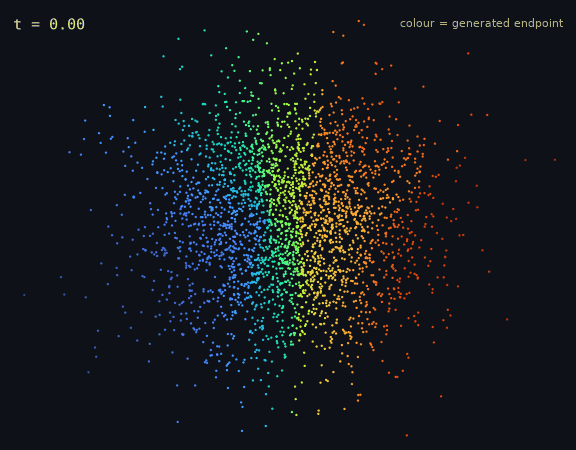

In [8]:
from IPython.display import Image as IPyImage, display
display(IPyImage(filename=str(OUT / "cl_flow_endpoint_colors.gif")))

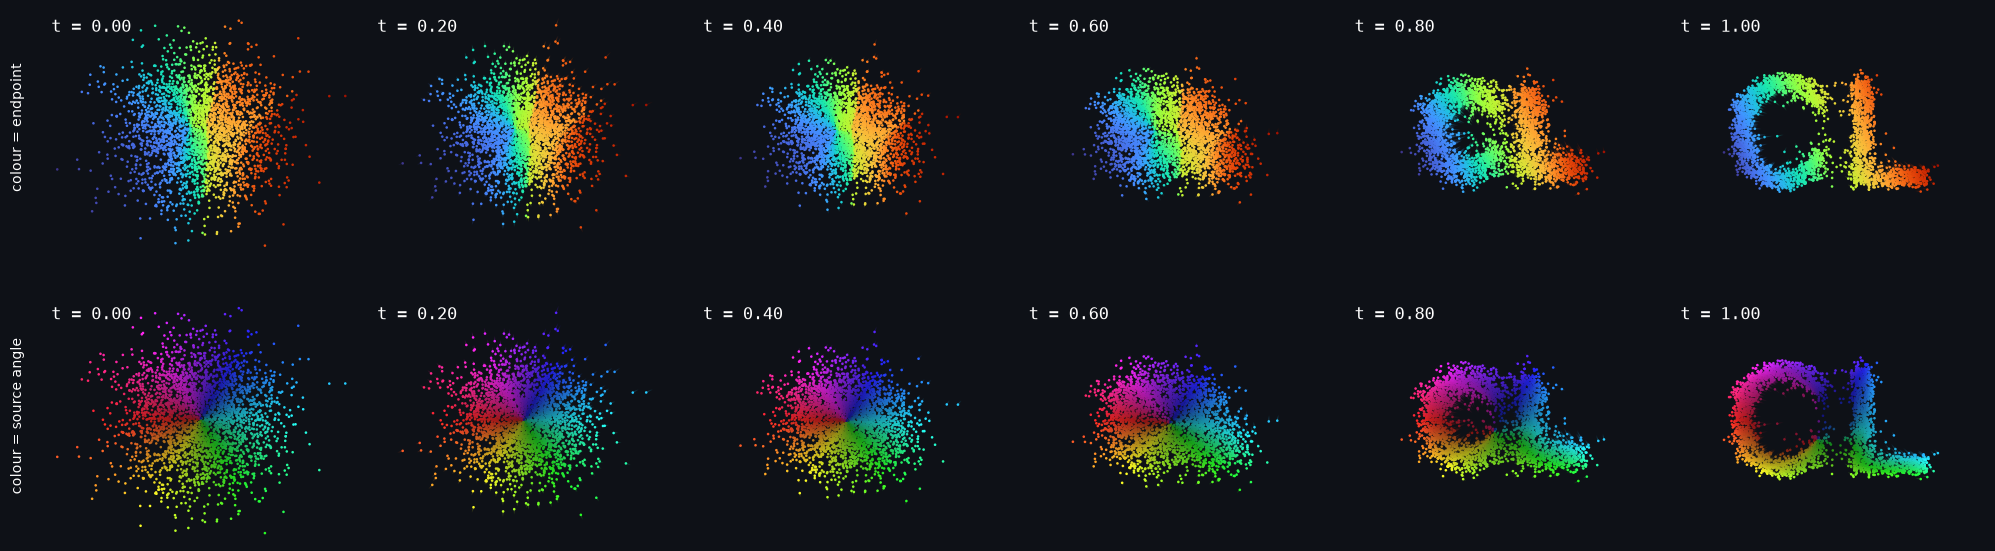

In [9]:
still_steps = [0, 20, 40, 60, 80, 100]
fig, axes = plt.subplots(2, len(still_steps), figsize=(20, 6.4))
fig.patch.set_facecolor(BG)
for j, k in enumerate(still_steps):
    draw_frame(axes[0, j], k, COLORS_END)
    draw_frame(axes[1, j], k, COLORS_SRC)
fig.text(0.005, 0.73, "colour = endpoint", color="white", rotation=90, va="center")
fig.text(0.005, 0.28, "colour = source angle", color="white", rotation=90, va="center")
plt.tight_layout(rect=(0.015, 0, 1, 1))
plt.savefig(OUT / "task2_still_frames.png", dpi=110, bbox_inches="tight", facecolor=BG)
plt.show()

The noise cloud is already colour-sorted at $t = 0$ (its left side becomes the C), and it is stretched and wrapped rather than torn.

## Task 3 — Sampling cost vs. quality

With fixed weights and fixed starting points, I compare Euler step counts using histogram TV (fixed grid plus an outside bin) and the on-letter rate.

In [10]:
N_EVAL = 40_000
STEP_COUNTS = [1, 2, 5, 10, 25, 50, 100, 200]
K_REF = 1000
BIN = 0.2
X_EDGES = np.arange(-4, 4 + 1e-9, BIN)
Y_EDGES = np.arange(-3, 3 + 1e-9, BIN)


def histogram_with_outside(points):
    """Normalised fixed-grid histogram, flattened, plus one final bin for all points outside the grid."""
    p = points.numpy() if torch.is_tensor(points) else points
    h, _, _ = np.histogram2d(p[:, 0], p[:, 1], bins=[X_EDGES, Y_EDGES])
    outside = len(p) - h.sum()
    return np.append(h.ravel(), outside) / len(p)


def tv_distance(a, b):
    return 0.5 * np.abs(histogram_with_outside(a) - histogram_with_outside(b)).sum()


z0_eval = sample_source(N_EVAL, torch.Generator().manual_seed(1000))
target_eval = sample_target(N_EVAL, torch.Generator().manual_seed(1001))
target_eval_2 = sample_target(N_EVAL, torch.Generator().manual_seed(1002))
noise_floor = tv_distance(target_eval, target_eval_2)

t0 = time.perf_counter()
z_ref = euler_sample(model, z0_eval, K_REF)
ref_seconds = time.perf_counter() - t0
print(f"noise floor (target vs. independent target): TV = {noise_floor:.4f}")
print(f"{K_REF}-step reference: TV to target = {tv_distance(z_ref, target_eval):.4f}, "
      f"on-letter = {on_letter_rate(z_ref):.3f}, {ref_seconds:.1f} s")

noise floor (target vs. independent target): TV = 0.0425
1000-step reference: TV to target = 0.1273, on-letter = 0.911, 103.1 s


In [11]:
def timed_sample(model, z0, k, repeats=3):
    """Median wall-clock of `repeats` runs of k-step Euler (network only, no plotting)."""
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        z = euler_sample(model, z0, k)
        times.append(time.perf_counter() - t0)
    return z, float(np.median(times))


rows, samples = [], {}
for k in STEP_COUNTS:
    z, sec = timed_sample(model, z0_eval, k)
    samples[k] = z
    rows.append({
        "steps": k,
        "network_evals_per_point": k,
        "sampling_seconds": sec,
        "ms_per_1000_points": 1000 * sec / N_EVAL * 1000,
        "TV_to_target": tv_distance(z, target_eval),
        "TV_to_1000step_ref": tv_distance(z, z_ref),
        "mean_dist_to_ref_endpoint": (z - z_ref).norm(dim=1).mean().item(),
        "on_letter_rate": on_letter_rate(z),
        "outside_grid_frac": histogram_with_outside(z)[-1],
    })
steps_df = pd.DataFrame(rows)
steps_df.to_csv(OUT / "task3_step_comparison.csv", index=False)
with pd.option_context("display.width", 200, "display.float_format", "{:.4f}".format):
    display(steps_df)

,steps,network_evals_per_point,sampling_seconds,ms_per_1000_points,TV_to_target,TV_to_1000step_ref,mean_dist_to_ref_endpoint,on_letter_rate,outside_grid_frac
0,1,1,0.1119,2.7970,0.9997,0.9973,1.7041,0.0001,0.0000
1,2,2,0.2177,5.4434,0.7028,0.7024,0.7603,0.3055,0.0000
2,5,5,0.5838,14.5953,0.3038,0.2745,0.2841,0.8422,0.0000
3,10,10,1.2493,31.2332,0.1963,0.1419,0.1423,0.8948,0.0000
4,25,25,3.1454,78.6350,0.1472,0.0613,0.0563,0.9095,0.0000
5,50,50,5.3796,134.4907,0.1343,0.0336,0.0275,0.9123,0.0000
6,100,100,10.3744,259.3607,0.1286,0.0189,0.0130,0.9118,0.0000
7,200,200,17.2319,430.7971,0.1274,0.0104,0.0058,0.9117,0.0000


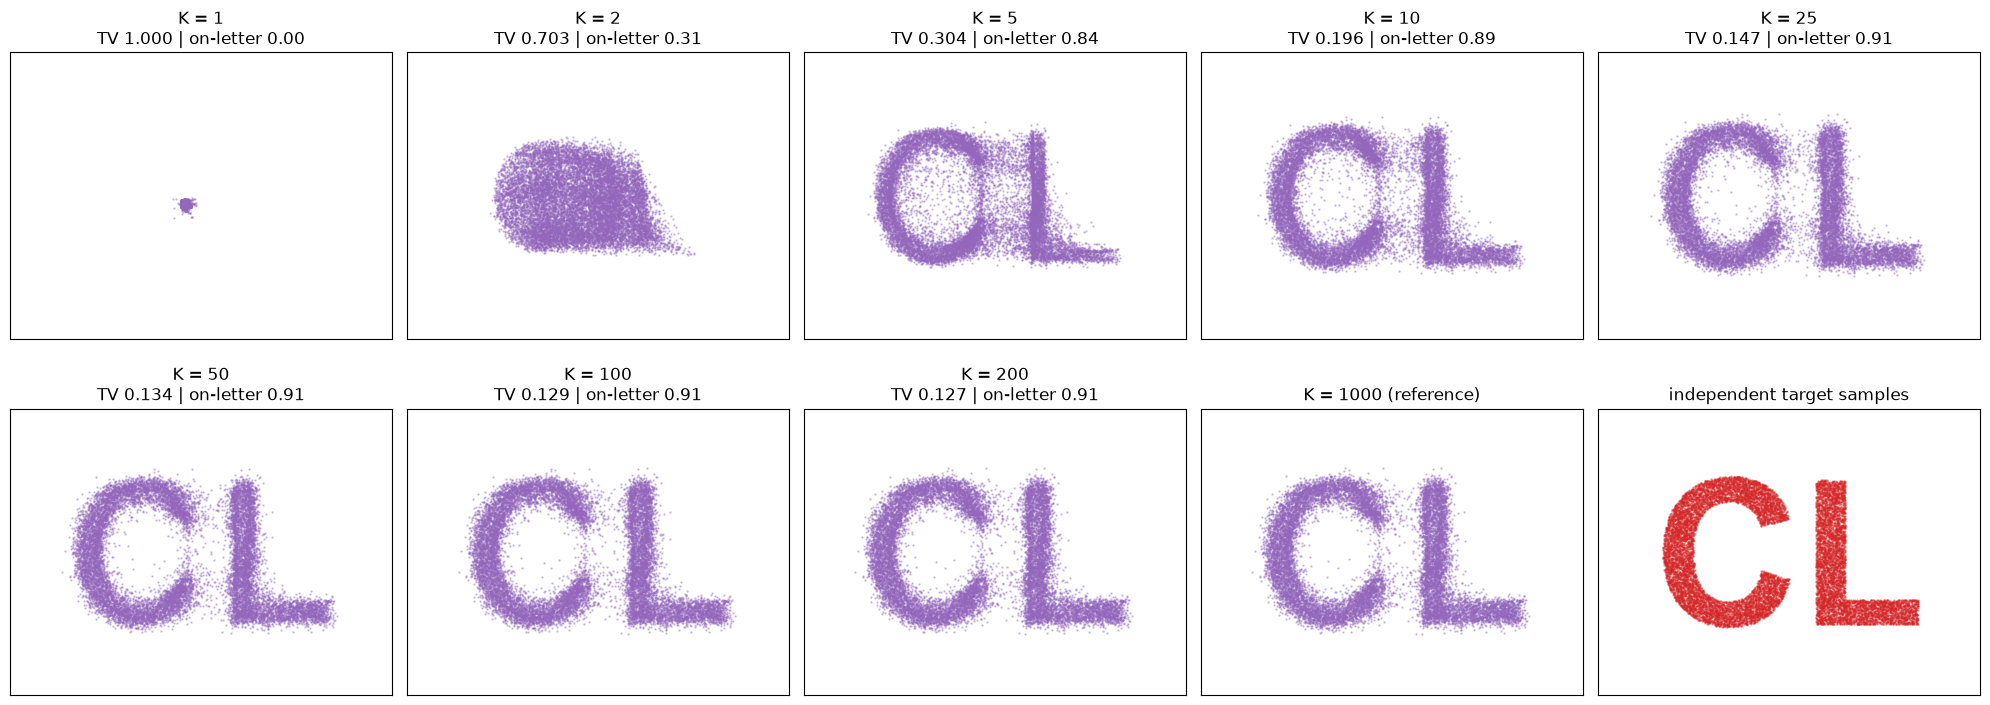

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7.6))
panels = [(f"K = {k}", samples[k], "tab:purple") for k in STEP_COUNTS] + \
         [(f"K = {K_REF} (reference)", z_ref, "tab:purple"), ("independent target samples", target_eval, "tab:red")]
for ax, (title, pts, col) in zip(axes.flat, panels):
    ax.scatter(*pts[:15000].T, s=0.6, alpha=0.35, color=col)
    if title.startswith("K = ") and "reference" not in title:
        r = steps_df.set_index("steps").loc[int(title.split("= ")[1])]
        title += f"\nTV {r.TV_to_target:.3f} | on-letter {r.on_letter_rate:.2f}"
    ax.set(xlim=(-4, 4), ylim=(-3, 3), aspect="equal", title=title)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(OUT / "task3_final_clouds_by_steps.png", dpi=120, bbox_inches="tight")
plt.show()

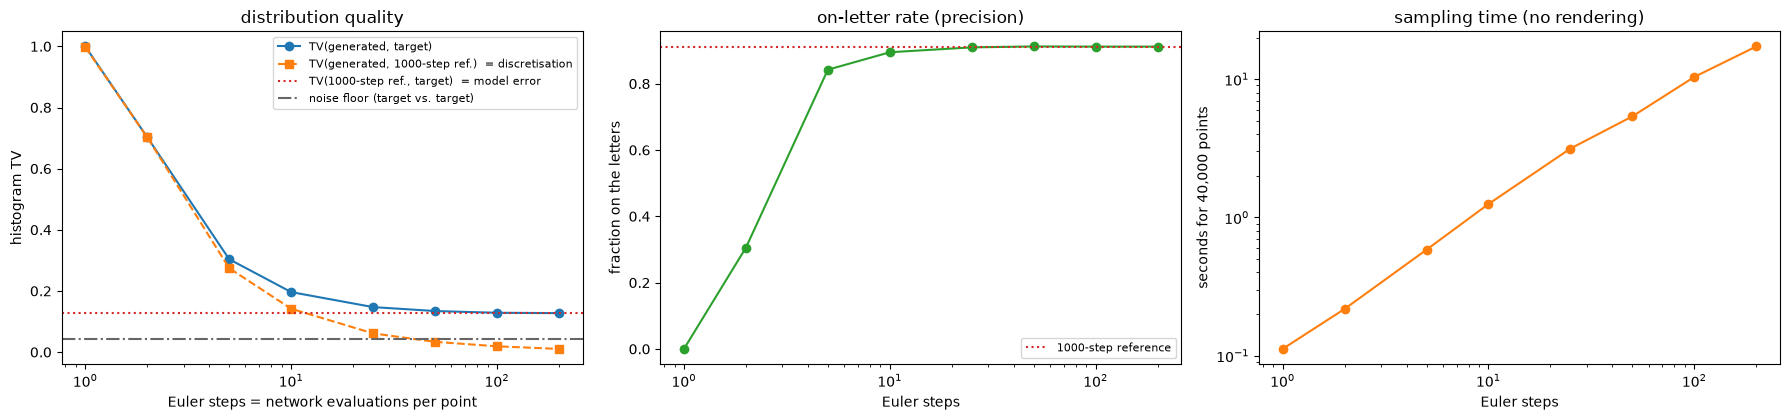

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
ax = axes[0]
ax.plot(steps_df.steps, steps_df.TV_to_target, "o-", label="TV(generated, target)")
ax.plot(steps_df.steps, steps_df.TV_to_1000step_ref, "s--", label=f"TV(generated, {K_REF}-step ref.)  = discretisation")
ax.axhline(tv_distance(z_ref, target_eval), color="tab:red", ls=":", label=f"TV({K_REF}-step ref., target)  = model error")
ax.axhline(noise_floor, color="0.4", ls="-.", label="noise floor (target vs. target)")
ax.set(xscale="log", xlabel="Euler steps = network evaluations per point", ylabel="histogram TV", title="distribution quality")
ax.legend(fontsize=8)
ax = axes[1]
ax.plot(steps_df.steps, steps_df.on_letter_rate, "o-", color="tab:green")
ax.axhline(on_letter_rate(z_ref), color="tab:red", ls=":", label=f"{K_REF}-step reference")
ax.set(xscale="log", xlabel="Euler steps", ylabel="fraction on the letters", title="on-letter rate (precision)")
ax.legend(fontsize=8)
ax = axes[2]
ax.plot(steps_df.steps, steps_df.sampling_seconds, "o-", color="tab:orange")
ax.set(xscale="log", yscale="log", xlabel="Euler steps", ylabel=f"seconds for {N_EVAL:,} points",
       title="sampling time (no rendering)")
plt.tight_layout()
plt.savefig(OUT / "task3_quality_vs_cost.png", dpi=130, bbox_inches="tight")
plt.show()

### Where the remaining error lives

Generated histogram (1,000 steps) minus target histogram: red cells have too much mass and blue cells too little.

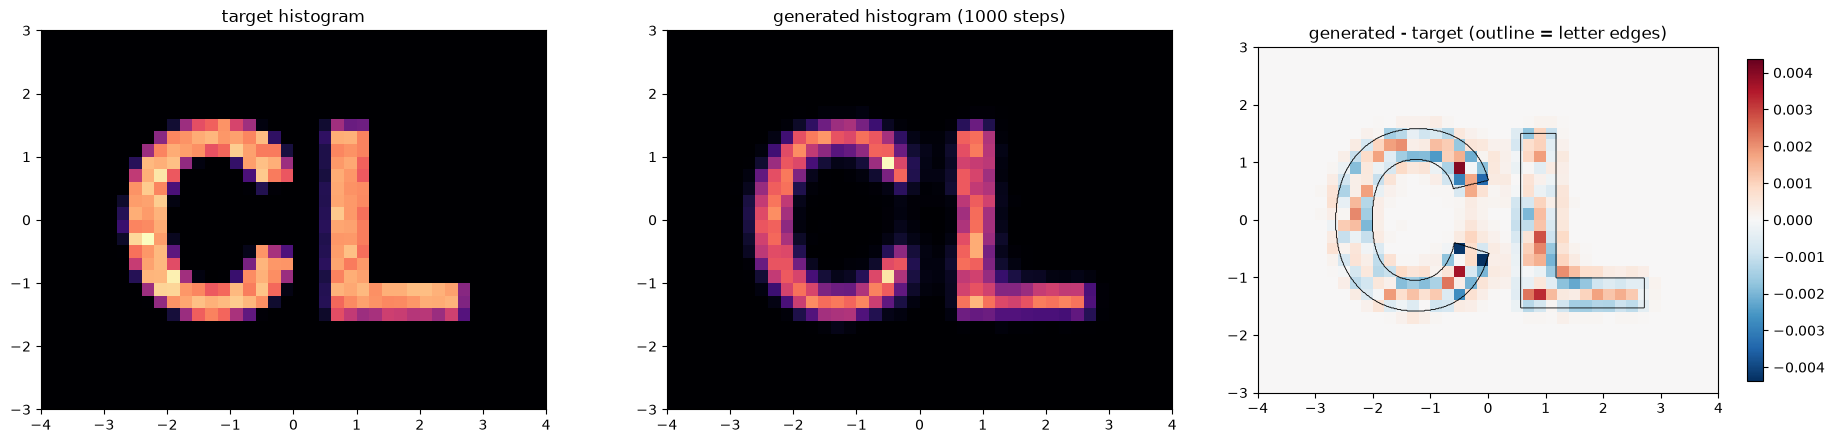

{'model_error_TV': np.float64(0.12725),
 'noise_floor_TV': np.float64(0.04250000000000001),
 'ref_on_letter': np.float64(0.911225),
 'pixel_size_units': 0.013303769401330377,
 'hist_bin_units': 0.2}

In [14]:
def grid_hist(points):
    p = points.numpy() if torch.is_tensor(points) else points
    return np.histogram2d(p[:, 0], p[:, 1], bins=[X_EDGES, Y_EDGES])[0].T / len(p)


diff = grid_hist(z_ref) - grid_hist(target_eval)
lim = np.abs(diff).max()
fig, axes = plt.subplots(1, 3, figsize=(19, 4.4))
for ax, img, title in [(axes[0], grid_hist(target_eval), "target histogram"),
                       (axes[1], grid_hist(z_ref), f"generated histogram ({K_REF} steps)")]:
    ax.imshow(img, origin="lower", extent=(-4, 4, -3, 3), cmap="magma")
    ax.set_title(title)
im = axes[2].imshow(diff, origin="lower", extent=(-4, 4, -3, 3), cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[2].contour(np.linspace(-W / 2 / SCALE, W / 2 / SCALE, W), np.linspace(H / 2 / SCALE, -H / 2 / SCALE, H),
                MASK.astype(float), levels=[0.5], colors="k", linewidths=0.6)
axes[2].set_title("generated - target (outline = letter edges)")
fig.colorbar(im, ax=axes[2], shrink=0.85)
plt.tight_layout()
plt.savefig(OUT / "task3_error_map.png", dpi=130, bbox_inches="tight")
plt.show()

ref_row = {"model_error_TV": tv_distance(z_ref, target_eval), "noise_floor_TV": noise_floor,
           "ref_on_letter": on_letter_rate(z_ref), "pixel_size_units": 1 / SCALE, "hist_bin_units": BIN}
(OUT / "task3_reference.json").write_text(json.dumps(ref_row, indent=2))
ref_row

Quality stops improving at about 50 steps, and the leftover error (soft edges, haze, piles at the C's tips) comes from the learned field, not the step count.